c:\Users\DELL\OneDrive\Desktop\University\Machine Learnng\Labs\PyCharmMiscProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 68.8M/68.8M [00:45<00:00, 1.60MB/s]

Extracting files...


C:\Users\DELL\.cache\kagglehub\datasets\zalando-research\fashionmnist\versions\4 ['fashion-mnist_test.csv', 'fashion-mnist_train.csv', 't10k-images-idx3-ubyte', 't10k-labels-idx1-ubyte', 'train-images-idx3-ubyte', 'train-labels-idx1-ubyte']
Shape: (60000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,4,0,0,0,5,4,5,5,3,5,...,7,8,7,4,3,7,5,0,0,0
6,4,0,0,0,0,0,0,0,0,0,...,14,0,0,0,0,0,0,0,0,0
7,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,4,0,0,0,0,0,0,3,2,0,...,1,0,0,0,0,0,0,0,0,0
9,8,0,0,0,0,0,0,0,0,0,...,203,214,166,0,0,0,0,0,0,0



Class distribution:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


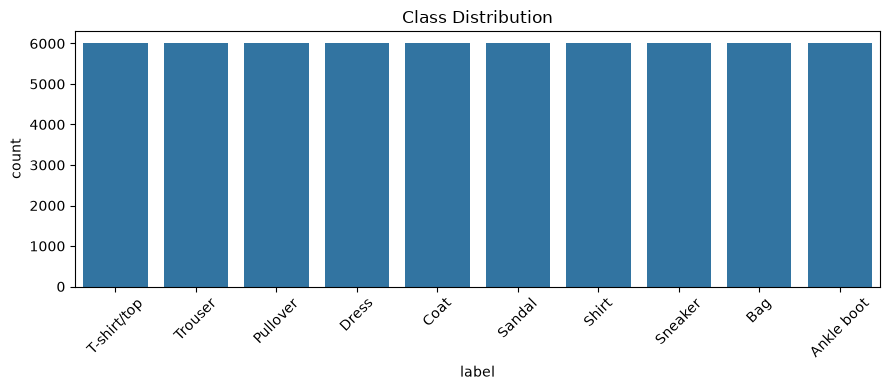

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import kagglehub, os

path = kagglehub.dataset_download("zalando-research/fashionmnist")
print(path, os.listdir(path))
df = pd.read_csv(os.path.join(path, "fashion-mnist_train.csv"))


print("Shape:", df.shape)
display(df.head(10))

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

plt.figure(figsize=(9, 4))
sns.countplot(x="label", data=df)
plt.xticks(range(10), class_names, rotation=45)
plt.title("Class Distribution")
plt.tight_layout()
plt.show()

In [3]:
X = df.drop("label", axis=1)
y = df["label"]

# Step 1: Normalize pixels from 0-255 to 0-1
X_norm = X / 255.0

# Step 2: StandardScaler (mean=0, std=1 per feature)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_norm)

print("Before scaling -> mean:", X_norm.values.mean().round(3), " std:", X_norm.values.std().round(3))
print("After scaling  -> mean:", X_scaled.mean().round(3), " std:", X_scaled.std().round(3))

Before scaling -> mean: 0.286  std: 0.353
After scaling  -> mean: 0.0  std: 1.0


In [4]:
n_original = X_scaled.shape[1]
results = {}

# Method 1: Fixed 50 components
pca1 = PCA(n_components=50, random_state=42)
X_pca1 = pca1.fit_transform(X_scaled)

# Method 2: 95% variance
pca2 = PCA(n_components=0.95, random_state=42)
X_pca2 = pca2.fit_transform(X_scaled)

# Method 3: All components
pca3 = PCA(n_components=None, random_state=42)
X_pca3 = pca3.fit_transform(X_scaled)

for name, p in [("Method 1: n_components=50", pca1),
                ("Method 2: n_components=0.95", pca2),
                ("Method 3: n_components=None", pca3)]:
    cum_var = p.explained_variance_ratio_.sum()
    results[name] = (n_original, p.n_components_, cum_var)
    print(f"{name}")
    print(f"  Original features     : {n_original}")
    print(f"  Retained components   : {p.n_components_}")
    print(f"  Cumulative variance   : {cum_var:.4f} ({cum_var*100:.2f}%)\n")

Method 1: n_components=50
  Original features     : 784
  Retained components   : 50
  Cumulative variance   : 0.8003 (80.03%)

Method 2: n_components=0.95
  Original features     : 784
  Retained components   : 256
  Cumulative variance   : 0.9502 (95.02%)

Method 3: n_components=None
  Original features     : 784
  Retained components   : 784
  Cumulative variance   : 1.0000 (100.00%)



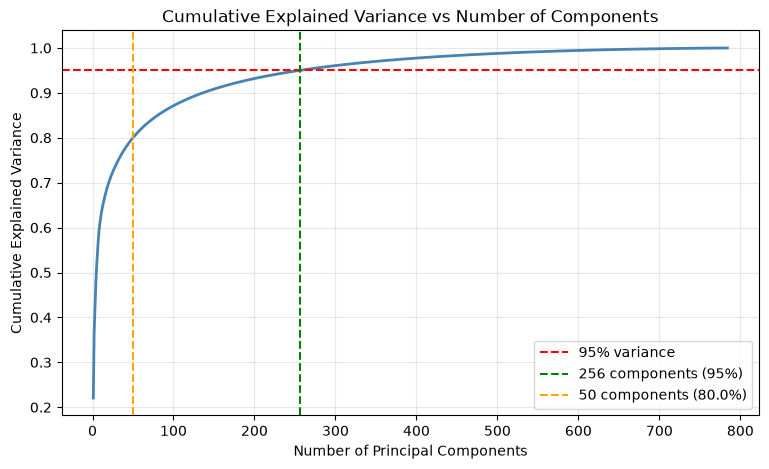

In [5]:
cum_var_all = np.cumsum(pca3.explained_variance_ratio_)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cum_var_all) + 1), cum_var_all, color="steelblue", lw=2)
plt.axhline(0.95, color="red", ls="--", label="95% variance")
plt.axvline(pca2.n_components_, color="green", ls="--",
            label=f"{pca2.n_components_} components (95%)")
plt.axvline(50, color="orange", ls="--",
            label=f"50 components ({cum_var_all[49]*100:.1f}%)")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance vs Number of Components")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:
comparison = pd.DataFrame({
    "Method": ["1: n_components=50", "2: n_components=0.95", "3: n_components=None"],
    "Original Features": [n_original] * 3,
    "Retained Components": [pca1.n_components_, pca2.n_components_, pca3.n_components_],
    "Cumulative Variance (%)": [pca1.explained_variance_ratio_.sum() * 100,
                                pca2.explained_variance_ratio_.sum() * 100,
                                pca3.explained_variance_ratio_.sum() * 100],
})
comparison["Dimensionality Reduction (%)"] = (
    (1 - comparison["Retained Components"] / n_original) * 100
)
display(comparison.round(2))

,Method,Original Features,Retained Components,Cumulative Variance (%),Dimensionality Reduction (%)
0,1: n_components=50,784,50,80.03,93.62
1,2: n_components=0.95,784,256,95.02,67.35
2,3: n_components=None,784,784,100.00,0.00
